# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

In [1]:
%pip install torch tensorflow pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## Step 1 — Import libraries

In [3]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
# from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [4]:
df = pd.read_csv("dataset/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [5]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [6]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

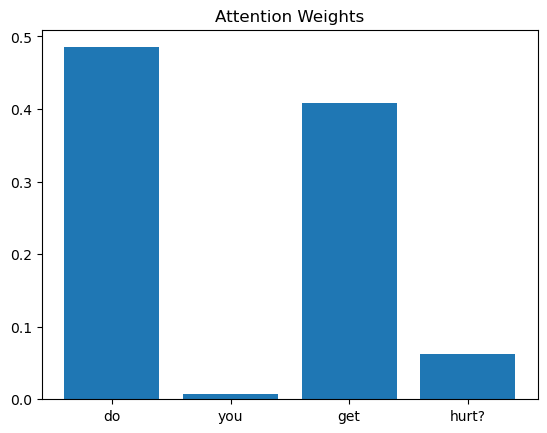

In [8]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: "do you get hurt?"
Highest attention: "do" (0.49)
Model's answer: I don't have a body.


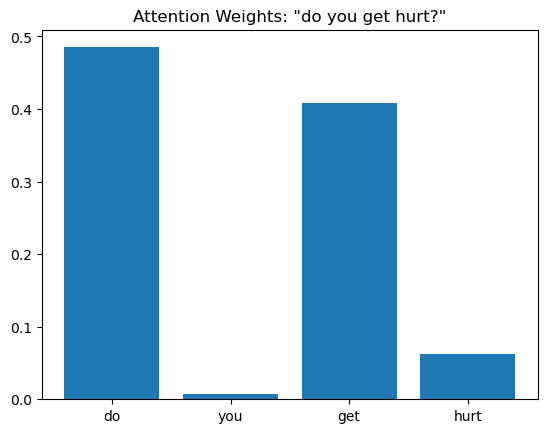


Question: "do you have a designer?"
Highest attention: "designer" (0.83)
Model's answer: I'm better at answering questions.


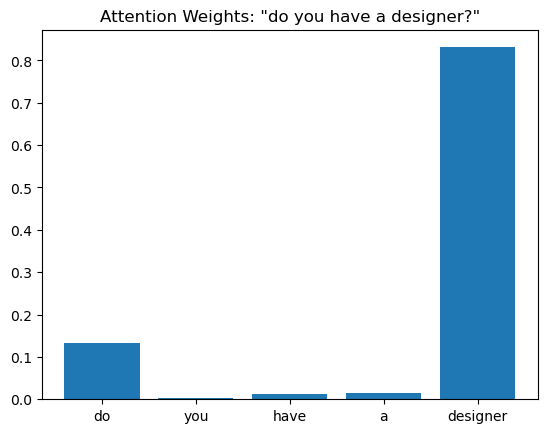


Question: "do you ever eat beef?"
Highest attention: "eat" (0.49)
Model's answer: Not at all.


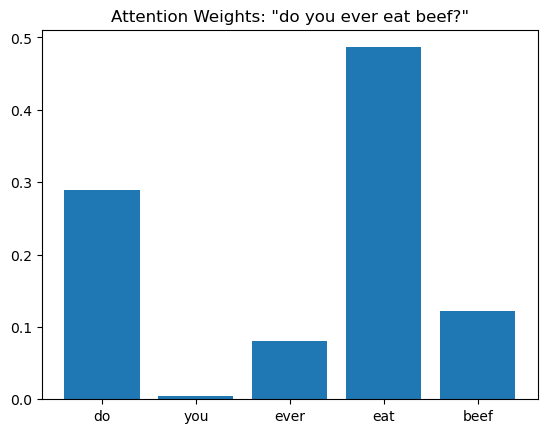

In [9]:
# Task 1 — attention for three different questions
answer_text = df.groupby("answer_id")["answer"].first()

def show_attention(i):
    question = df["question"][i]
    # words come from the tokenizer so they line up with the model input (no "?" or padding)
    words = [tokenizer.index_word[t] for t in X[i].tolist() if t != 0]

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])
    w = weights[0, :len(words)].tolist()

    top_word = words[w.index(max(w))]
    print(f'Question: "{question}"')
    print(f'Highest attention: "{top_word}" ({max(w):.2f})')
    print("Model's answer:", answer_text[prediction.argmax(1).item()])

    plt.bar(words, w)
    plt.title(f'Attention Weights: "{question}"')
    plt.show()
    return top_word

for i in [0, 49, 99]:
    show_attention(i)
    print()

**Answer:**

| Question | Highest-attention word | Weight |
|---|---|---|
| do you get hurt? | do | 0.49 |
| do you have a designer? | designer | 0.83 |
| do you ever eat beef? | eat | 0.49 |

Partly. For "do you have a designer?" and "do you ever eat beef?", the highest weight falls on the word that identifies the topic ("designer", "eat"). For "do you get hurt?", it falls on "do", a function word that starts questions in many different answer groups, while the key word "hurt" receives only about 0.06. High attention on the right word also did not guarantee the right answer: two of the three questions were misclassified. Attention shows which hidden states the model relied on, not what a human would consider important. Because this model is weakly trained, its attention is noisy.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: "how old are you?"
Highest attention: "are" (0.67)
Model's answer: People created me.


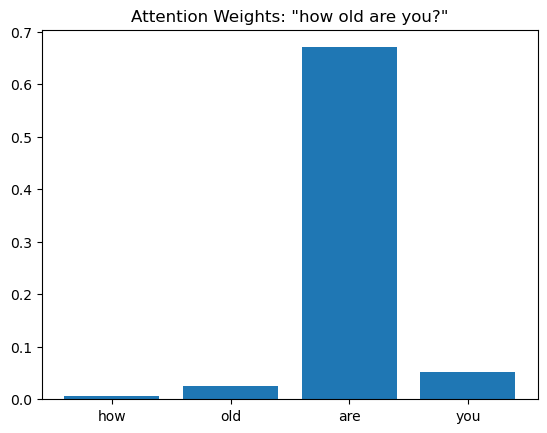

Question: "what's your age?"
Highest attention: "age" (0.83)
Model's answer: Not at all.


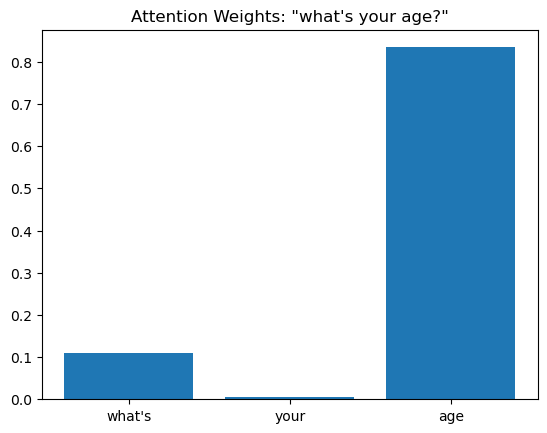

Highest-attention words: "are" vs "age"


In [10]:
# Task 2 — two questions with the same meaning (both should get "Age doesn't really apply to me.")
top1 = show_attention(24)   # "how old are you?"
top2 = show_attention(20)   # "what's your age?"
print(f'Highest-attention words: "{top1}" vs "{top2}"')

**Answer:**

| Question | Highest-attention word | Weight |
|---|---|---|
| how old are you? | are | 0.67 |
| what's your age? | age | 0.83 |

The model focuses on different words. For "what's your age?" it attends to "age", the word that carries the meaning, but for "how old are you?" it attends to "are" and gives almost no weight to "old" (0.03). Neither question received the correct answer. This suggests that attention operates on the learned representations of specific tokens rather than on meaning. The embeddings are trained from scratch on only 168 questions, so the model has not learned that "old" and "age" are related. Attention can only highlight words the model already finds useful; with better training, more data or pretrained embeddings, similar questions should focus on equivalent words.